# House Price Analysis and Prediction | King County, Washington

## Project Goal
The goal of this project is to analyze residential property sales in King County, Washington, and identify the key factors that influence house prices. Using historical housing data, the analysis explores how property characteristics such as living area, number of bedrooms, bathrooms, floors, construction grade, and waterfront status relate to selling prices.

The project also focuses on developing and evaluating regression models to predict house prices based on these characteristics. By comparing model performance, the analysis aims to identify approaches that provide more reliable price estimates and generate insights that can support informed decisions in residential real estate investment.

## Objectives
- Load and review the housing dataset.
- Prepare the data by removing unnecessary columns and handling missing values.
- Explore house prices using summary statistics and visualizations.
- Develop linear and polynomial regression models.
- Evaluate Ridge regression models using separate training and testing data.

## Tools Used
- **Python:** Data analysis and modeling.
- **Pandas and NumPy:** Data preparation and numerical calculations.
- **Matplotlib and Seaborn:** Charts and visual exploration.
- **Scikit-learn:** Regression, preprocessing, and model evaluation.
- **Jupyter Notebook:** Code, results, and documentation.

## About the Dataset

The dataset records home sales in King County, Washington, including Seattle, from May 2014 to May 2015. It is a course-modified version of the [King County House Sales dataset](https://www.kaggle.com/datasets/harlfoxem/housesalesprediction). The target variable is `price`.

| Variable      | Description                                                                                                 |
| ------------- | ----------------------------------------------------------------------------------------------------------- |
| id            | A notation for a house                                                                                      |
| date          | Date house was sold                                                                                         |
| price         | Price is prediction target                                                                                  |
| bedrooms      | Number of bedrooms                                                                                          |
| bathrooms     | Number of bathrooms                                                                                         |
| sqft_living   | Square footage of the home                                                                                  |
| sqft_lot      | Square footage of the lot                                                                                   |
| floors        | Total floors (levels) in house                                                                              |
| waterfront    | House which has a view to a waterfront                                                                      |
| view          | Has been viewed                                                                                             |
| condition     | How good the condition is overall                                                                           |
| grade         | overall grade given to the housing unit, based on King County grading system                                |
| sqft_above    | Square footage of house apart from basement                                                                 |
| sqft_basement | Square footage of the basement                                                                              |
| yr_built      | Built Year                                                                                                  |
| yr_renovated  | Year when house was renovated                                                                               |
| zipcode       | Zip code                                                                                                    |
| lat           | Latitude coordinate                                                                                         |
| long          | Longitude coordinate                                                                                        |
| sqft_living15 | Living room area in 2015(implies-- some renovations) This might or might not have affected the lotsize area |
| sqft_lot15    | LotSize area in 2015(implies-- some renovations)                                                            |


## Import Libraries

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

%matplotlib inline

print("All libraries imported successfully!")


All libraries imported successfully!


## 1. Load and Inspect the Data

Load the housing data into a Pandas DataFrame.

In [3]:
filepath='https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-SkillsNetwork/labs/FinalModule_Coursera/data/kc_house_data_NaN.csv'
df = pd.read_csv(filepath)

Display the first five records to check the dataset structure.

In [5]:
df.head()

,Unnamed: 0,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,0,7129300520,20141013T000000,221900.0,3.0,1.00,1180,5650,1.0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,1,6414100192,20141209T000000,538000.0,3.0,2.25,2570,7242,2.0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,2,5631500400,20150225T000000,180000.0,2.0,1.00,770,10000,1.0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,3,2487200875,20141209T000000,604000.0,4.0,3.00,1960,5000,1.0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,4,1954400510,20150218T000000,510000.0,3.0,2.00,1680,8080,1.0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


### Question 1

Display the data types of each column using the function dtypes.

In [7]:

df.dtypes


Unnamed: 0         int64
id                 int64
date              object
price            float64
bedrooms         float64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object

Review summary statistics for the numerical columns.

In [9]:
df.describe()

,Unnamed: 0,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,21613.00000,2.161300e+04,2.161300e+04,21600.000000,21603.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,...,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,10806.00000,4.580302e+09,5.400881e+05,3.372870,2.115736,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,...,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,6239.28002,2.876566e+09,3.671272e+05,0.926657,0.768996,918.440897,4.142051e+04,0.539989,0.086517,0.766318,...,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,0.00000,1.000102e+06,7.500000e+04,1.000000,0.500000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,...,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,5403.00000,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,...,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,10806.00000,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,...,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,16209.00000,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,...,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,21612.00000,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,...,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


## 2. Data Wrangling

### Question 2

Drop the columns <code>"id"</code>  and <code>"Unnamed: 0"</code> from axis 1 using the method <code>drop()</code>, then use the method <code>describe()</code> to obtain a statistical summary of the data. Make sure the <code>inplace</code> parameter is set to <code>True</code>.

In [11]:

df.drop(["id", "Unnamed: 0"], axis=1, inplace=True)

df.describe()


,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,21600.000000,21603.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,5.400881e+05,3.372870,2.115736,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,3.671272e+05,0.926657,0.768996,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,7.500000e+04,1.000000,0.500000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


### Handle Missing Values
- Check the `bedrooms` and `bathrooms` columns for missing values.
- Replace missing values in each column with its mean.
- Check both columns again to confirm that no missing values remain.

In [13]:
print("number of NaN values for the column bedrooms :", df['bedrooms'].isnull().sum())
print("number of NaN values for the column bathrooms :", df['bathrooms'].isnull().sum())


number of NaN values for the column bedrooms : 13
number of NaN values for the column bathrooms : 10


In [15]:
mean = df['bedrooms'].mean()
df['bedrooms'] = df['bedrooms'].replace(np.nan, mean)

In [17]:
mean = df['bathrooms'].mean()
df['bathrooms'] = df['bathrooms'].replace(np.nan, mean)

In [19]:
print("number of NaN values for the column bedrooms :", df['bedrooms'].isnull().sum())
print("number of NaN values for the column bathrooms :", df['bathrooms'].isnull().sum())

number of NaN values for the column bedrooms : 0
number of NaN values for the column bathrooms : 0


## 3. Exploratory Data Analysis

### Question 3

Use the method <code>value_counts</code> to count the number of houses with unique floor values, use the method <code>.to_frame()</code> to convert it to a data frame.

In [21]:

df['floors'].value_counts().to_frame()


,count
floors,
1.0,10680
2.0,8241
1.5,1910
3.0,613
2.5,161
3.5,8


**Finding:** Single-floor homes (`floors = 1.0`) are the most common, with 10,680 records.

### Question 4

Use the function <code>boxplot</code> in the seaborn library  to  determine whether houses with a waterfront view or without a waterfront view have more price outliers.

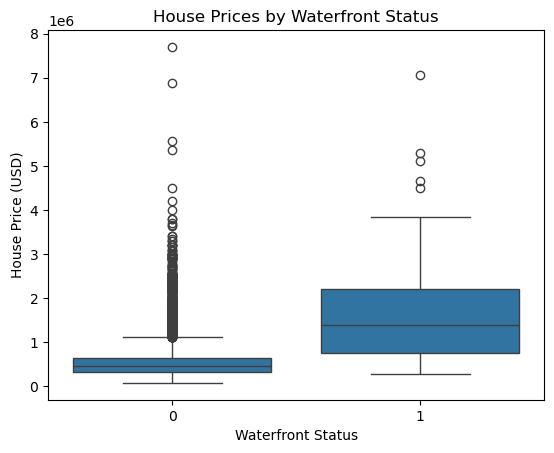

In [23]:

sns.boxplot(x="waterfront", y="price", data=df)

plt.title("House Prices by Waterfront Status")
plt.xlabel("Waterfront Status")
plt.ylabel("House Price (USD)")

plt.show()


**Finding:** The box plot shows that houses without waterfront views have more price outliers than waterfront properties. However, waterfront homes generally have higher median selling prices and a wider spread of prices.
This suggests that waterfront location is associated with higher property values, although house prices still vary considerably within both groups.

### Question 5

Use the function <code>regplot</code>  in the seaborn library  to  determine if the feature <code>sqft_above</code> is negatively or positively correlated with price.

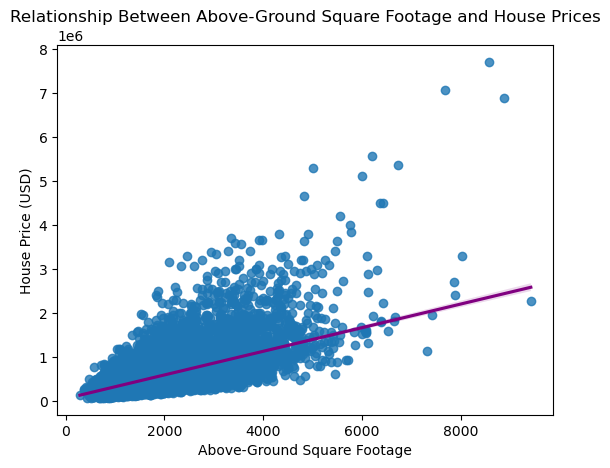

In [27]:

sns.regplot(x="sqft_above", y="price", data=df,
            line_kws={"color": "purple"})

plt.title("Relationship Between Above-Ground Square Footage and House Prices")
plt.xlabel("Above-Ground Square Footage")
plt.ylabel("House Price (USD)")

plt.show()


**Finding:** The regression plot shows a positive relationship between above-ground living area (`sqft_above`) and house prices. Houses with more above-ground living space generally have higher selling prices, although prices vary among properties of similar sizes. This suggests that above-ground living area is an important factor associated with house prices, but it does not explain all price differences.

Calculate correlations with `price` to see which numerical features have the strongest linear relationships.

In [29]:
df_numeric = df.select_dtypes(include=[np.number])
df_numeric.corr()['price'].sort_values()

zipcode         -0.053203
long             0.021626
condition        0.036362
yr_built         0.054012
sqft_lot15       0.082447
sqft_lot         0.089661
yr_renovated     0.126434
floors           0.256794
waterfront       0.266369
lat              0.307003
bedrooms         0.308797
sqft_basement    0.323816
view             0.397293
bathrooms        0.525738
sqft_living15    0.585379
sqft_above       0.605567
grade            0.667434
sqft_living      0.702035
price            1.000000
Name: price, dtype: float64

**Finding:** `sqft_living` has the strongest positive correlation with price among the numerical predictors (approximately 0.702), followed by `grade` (approximately 0.667). Correlation does not establish causation.

## 4. Model Development

Fit a baseline linear regression using longitude (`long`) and calculate its training R².

In [31]:
X = df[['long']]
Y = df['price']

lm = LinearRegression()
lm.fit(X,Y)
lm.score(X, Y)

0.00046769430149007363

**Finding:** Longitude alone explains very little of the variation in sale prices (training R² ≈ 0.0005).

### Question  6

Fit a linear regression model to predict the <code>'price'</code> using the feature <code>'sqft_living'</code> then calculate the R^2.

In [35]:

X = df[['sqft_living']]
Y = df['price']

lm = LinearRegression()
lm.fit(X, Y)
lm.score(X, Y)


0.4928532179037931

**Finding:** Using living area alone produces a training R² of 0.4929, explaining approximately 49.29% of the variation in prices in this dataset.

### Question 7

Fit a linear regression model to predict the <code>'price'</code> using the list of features:


In [ ]:
features =["floors", "waterfront","lat" ,"bedrooms" ,"sqft_basement" ,"view" ,"bathrooms","sqft_living15","sqft_above","grade","sqft_living"]     

Calculate the training R² using the listed housing features.

In [37]:

features = [
    "floors", "waterfront", "lat", "bedrooms",
    "sqft_basement", "view", "bathrooms",
    "sqft_living15", "sqft_above", "grade",
    "sqft_living"
]

X = df[features]
Y = df["price"]

lm = LinearRegression()
lm.fit(X, Y)
lm.score(X, Y)


0.6576951666037496

**Finding:**  The multiple linear regression model achieved a training R² of **0.6577 (65.77%)**, compared with **0.4929 (49.29%)** when using living area alone. This improvement suggests that combining several housing features provides a better fit to the training data than relying on living area alone.

### Question 8 

Create a pipeline using `StandardScaler`, `PolynomialFeatures`, and `LinearRegression` to predict `price`.

In [39]:
Input=[('scale',StandardScaler()),('polynomial', PolynomialFeatures(include_bias=False)),('model',LinearRegression())]



Use the list to create a pipeline object to predict the 'price', fit the object using the features in the list <code>features</code>, and calculate the R^2.

In [41]:

pipe = Pipeline(Input)

X = df[features]
Y = df["price"]

pipe.fit(X, Y)
pipe.score(X, Y)


0.7513404110730729

**Finding:** The polynomial regression pipeline achieves a training R² of 0.7513 (75.13%), the highest training score among the models evaluated so far. This does not by itself establish how well the model predicts new sales.

## 5. Model Evaluation and Refinement

Import the model evaluation functions 

In [43]:
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split
print("done")

done


Split the data into training (85%) and testing (15%) subsets.

In [45]:
features =["floors", "waterfront","lat" ,"bedrooms" ,"sqft_basement" ,"view" ,"bathrooms","sqft_living15","sqft_above","grade","sqft_living"]    
X = df[features]
Y = df['price']

x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.15, random_state=1)


print("number of test samples:", x_test.shape[0])
print("number of training samples:",x_train.shape[0])

number of test samples: 3242
number of training samples: 18371


### Question 9

Create and fit a Ridge regression object using the training data, set the regularization parameter to 0.1, and calculate the R^2 using the test data.

In [47]:
from sklearn.linear_model import Ridge

In [49]:

RidgeModel = Ridge(alpha=0.1)

RidgeModel.fit(x_train, y_train)

print(RidgeModel.score(x_test, y_test))


0.6478759163939113


**Test result:** Ridge regression with `alpha=0.1` achieves an R² of 0.6479 (64.79%) on the test data.

### Question 10

Perform a second order polynomial transform on both the training data and testing data. Create and fit a Ridge regression object using the training data, set the regularisation parameter to 0.1, and calculate the R^2 utilising the test data provided.

In [51]:

pr = PolynomialFeatures(degree=2)

x_train_pr = pr.fit_transform(x_train)
x_test_pr = pr.transform(x_test)

RidgeModel = Ridge(alpha=0.1)
RidgeModel.fit(x_train_pr, y_train)
print(RidgeModel.score(x_test_pr, y_test))


0.7002744268644931


**Test result:** Applying a second-order polynomial transformation followed by Ridge regression (`alpha=0.1`) gives a test R² of 0.7003 (70.03%). This is approximately 5.24 percentage points higher than the result in Question 9.

## Model Results and Conclusion

| Model | R² | Data used for scoring |
|---|---:|---|
| Linear regression — longitude | 0.0005 | Training |
| Linear regression — living area | 0.4929 | Training |
| Multiple linear regression | 0.6577 | Training |
| Regression pipeline (`StandardScaler`, `PolynomialFeatures`, `LinearRegression`) | 0.7513 | Training |
| Ridge regression (`alpha=0.1`) | 0.6479 | Testing |
| Second-order polynomial transformation and Ridge regression (`alpha=0.1`) | 0.7003 | Testing |


The analysis found that larger living areas and higher construction grades were strongly associated with higher house prices. Using multiple housing features improved the model's training R² compared with using living area alone, while the regression pipeline achieved a training R² of **0.7513 (75.13%)**.

On the test data, Ridge regression achieved an R² of **0.6479 (64.79%)**, which increased to **0.7003 (70.03%)** after applying a second-order polynomial transformation. This shows that the transformation improved the model's predictive performance on the test dataset.

Overall, the results highlight the importance of selecting relevant housing features and comparing regression approaches when predicting property prices. Further evaluation using cross-validation and additional error measures, such as MAE , could help assess model reliability.

**Acknowledgment:** This project was completed as part of the IBM Data Analyst Professional Certificate on Coursera, using materials provided by IBM Skills Network.